In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in r18b05gal4_r60d05lexa_analysis.py next to this notebook
# (run it as a script to regenerate everything: python r18b05gal4_r60d05lexa_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import r18b05gal4_r60d05lexa_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
sess_manager.sess_df.head()

,date,fly,sess,fictrac_scan_num,closed_loop,dark,rnai_line,gal4_line,usable,fictrac_dat_file,notes,session,fly_id,rnai
0,29_03_2024,fly2,closed_loop-000,0,1,0,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,closed_loop-000,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
1,29_03_2024,fly2,dark-001,1,0,1,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,dark-001,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
2,29_03_2024,fly2,closed_loop-002,2,2,0,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,closed_loop-002,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
3,29_03_2024,fly2,dark-003,3,0,1,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,dark-003,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
5,01_04_2024,fly1,closed_loop-000,0,1,0,rnai_67968,R18B05,1,fictrac-20240401_162130.dat,NaN,closed_loop-000,01_04_2024_fly1_R18B05_rnai_67968,rnai_67968


## Offset vector length and variance, dark vs closed loop

offset_var_mixed_anova


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,rnai,5.703769,2,26,2.851885,8.355904,1.575906e-03,0.391269,NaN
1,dark,13.453716,1,26,13.453716,42.169372,6.973457e-07,0.618597,1.0
2,Interaction,4.665180,2,26,2.332590,7.311278,3.024679e-03,0.359962,NaN


offset_var_pairwise_dark_effect


,Contrast,rnai,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,rnai,-,control,gal4_control,False,True,-1.174686,18.000000,two-sided,0.255427,0.255427,holm,0.642,-0.503138
1,rnai,-,control,rnai_67968,False,True,-3.540488,11.830819,two-sided,0.004153,0.012459,holm,14.544,-1.603831
2,rnai,-,gal4_control,rnai_67968,False,True,-2.639261,13.027992,two-sided,0.020395,0.040789,holm,3.527,-1.187919
3,dark,-,0,1,True,True,-5.391306,28.000000,two-sided,0.000010,NaN,NaN,2218.885,-1.355140
4,rnai * dark,control,0,1,True,True,-6.471329,9.000000,two-sided,0.000115,0.000346,holm,252.953,-2.967612
5,rnai * dark,gal4_control,0,1,True,True,-4.199190,9.000000,two-sided,0.002309,0.004619,holm,20.416,-2.059739
6,rnai * dark,rnai_67968,0,1,True,True,-0.514821,8.000000,two-sided,0.620597,0.620597,holm,0.36,-0.173978


offset_var_pairwise_group_effect


,Contrast,dark,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,dark,-,0,1,True,True,-5.391306,28.000000,two-sided,0.000010,NaN,NaN,2218.885,-1.355140
1,rnai,-,control,gal4_control,False,True,-1.174686,18.000000,two-sided,0.255427,0.255427,holm,0.642,-0.503138
2,rnai,-,control,rnai_67968,False,True,-3.540488,11.830819,two-sided,0.004153,0.012459,holm,14.544,-1.603831
3,rnai,-,gal4_control,rnai_67968,False,True,-2.639261,13.027992,two-sided,0.020395,0.040789,holm,3.527,-1.187919
4,dark * rnai,0,control,gal4_control,False,True,-1.091458,18.000000,two-sided,0.289466,1.000000,holm,0.602,-0.467490
5,dark * rnai,0,control,rnai_67968,False,True,-6.692343,15.194985,two-sided,0.000007,0.000040,holm,3264.242,-2.976178
6,dark * rnai,0,gal4_control,rnai_67968,False,True,-4.701261,16.994962,two-sided,0.000206,0.001029,holm,107.251,-2.048685
7,dark * rnai,1,control,gal4_control,False,True,-0.401342,18.000000,two-sided,0.692893,1.000000,holm,0.421,-0.171902
8,dark * rnai,1,control,rnai_67968,False,True,-0.324516,13.326341,two-sided,0.750585,1.000000,holm,0.42,-0.145831
9,dark * rnai,1,gal4_control,rnai_67968,False,True,0.000575,14.992291,two-sided,0.999549,1.000000,holm,0.405,0.000256


offset_n_flies


,rnai,n_flies
0,control,10
1,gal4_control,10
2,rnai_67968,9


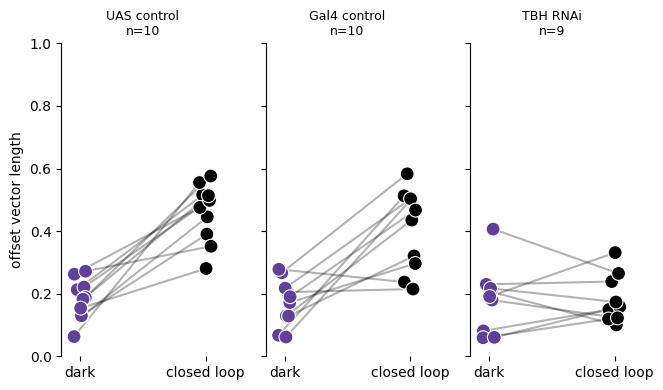

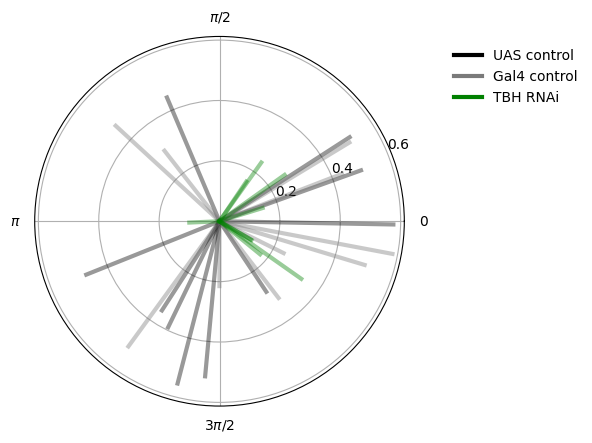

In [3]:
offset_unique, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PV magnitude vs rotation speed

In [ ]:
rho_grouped, rho_tables = ana.rho_analysis(sess_manager)
for name, table in rho_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PVA velocity vs rotation speed

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/group_comparison.py:175: RuntimeWarning: Mean of empty slice
  lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


dphi_ols_closed_loop
                            OLS Regression Results                            
Dep. Variable:                   dphi   R-squared:                       0.443
Model:                            OLS   Adj. R-squared:                  0.438
Method:                 Least Squares   F-statistic:                     87.73
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           8.20e-68
Time:                        16:24:55   Log-Likelihood:                -433.73
No. Observations:                 558   AIC:                             879.5
Df Residuals:                     552   BIC:                             905.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

,condition,terms,F,p
0,closed_loop,slope differences (dh:group),0.894785,0.409287
1,closed_loop,intercept differences (group),1.974994,0.139741
2,dark,slope differences (dh:group),9.257147,0.000109
3,dark,intercept differences (group),0.275823,0.759041


dphi_coefficients


,condition,term,coef,p,p_holm
0,closed_loop,"dh:C(rnai, Treatment(""rnai_67968""))[T.control]",0.011506,0.804679,0.804679
1,closed_loop,"dh:C(rnai, Treatment(""rnai_67968""))[T.gal4_con...",-0.044355,0.337906,0.675811
2,dark,"dh:C(rnai, Treatment(""rnai_67968""))[T.control]",0.180148,0.000020,0.000039
3,dark,"dh:C(rnai, Treatment(""rnai_67968""))[T.gal4_con...",0.097161,0.023740,0.023740


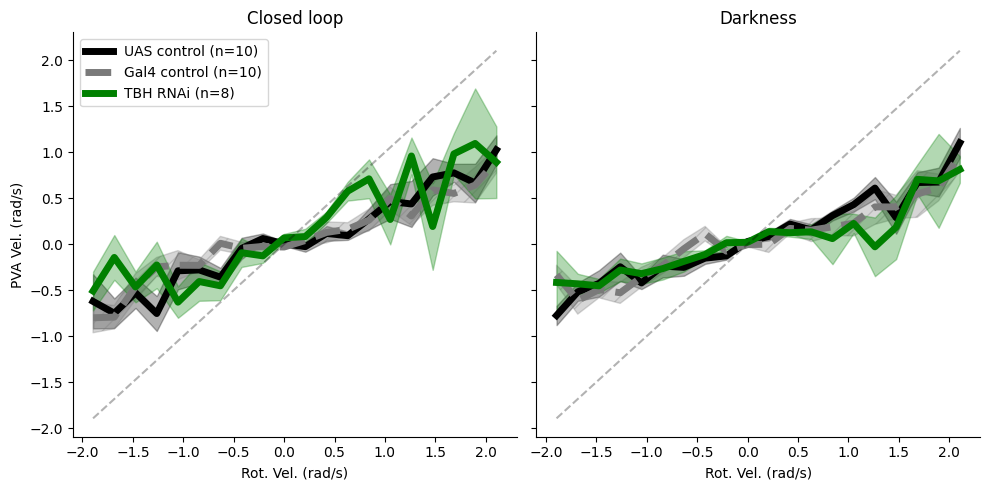

In [ ]:
dphi_grouped, dphi_tables = ana.dphi_analysis(sess_manager)
for name, table in dphi_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Bump width

bump_width_tests


,family,comparison,n,W,p,p_holm
0,closed loop vs dark,UAS control,10.0,10.0,0.083984,0.251953
1,closed loop vs dark,Gal4 control,9.0,13.0,0.300781,0.601562
2,closed loop vs dark,TBH RNAi,8.0,17.0,0.945312,0.945312
3,"closed loop, between groups",UAS control vs Gal4 control,NaN,50.0,0.713303,0.713303
4,"closed loop, between groups",UAS control vs TBH RNAi,NaN,5.0,0.000868,0.002605
5,"closed loop, between groups",Gal4 control vs TBH RNAi,NaN,5.0,0.001563,0.003126


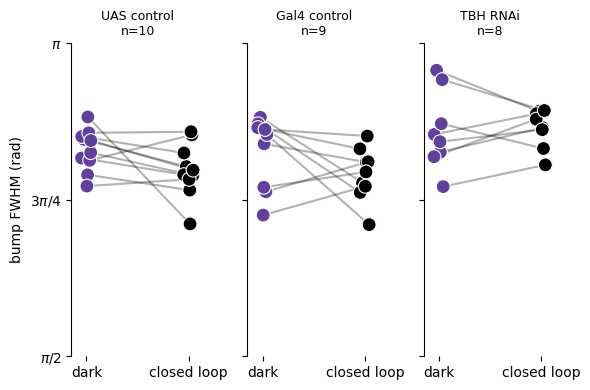

In [ ]:
widths, width_tables = ana.width_analysis(sess_manager)
for name, table in width_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Closed-loop and dark heatmaps of every fly

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/plotting.py:231: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=figsize)


29

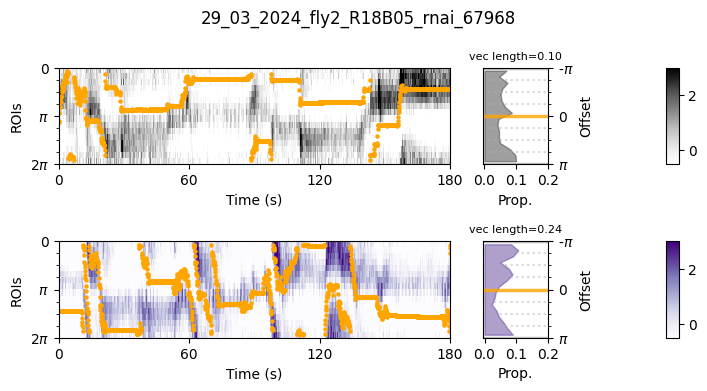

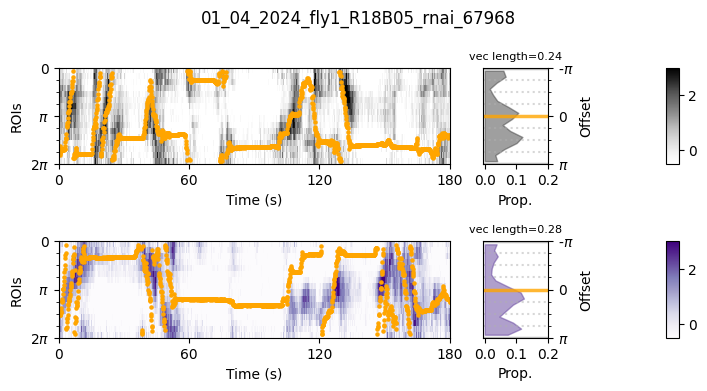

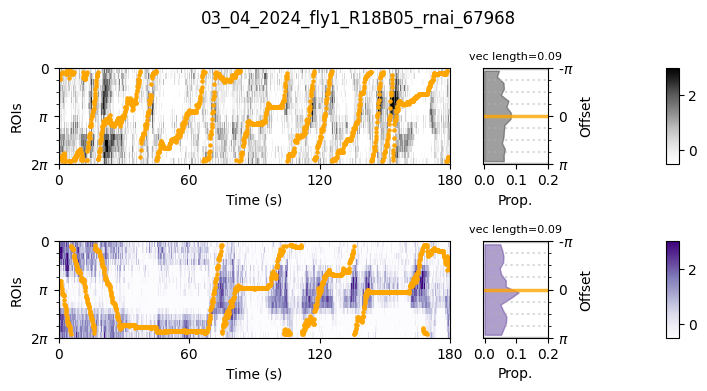

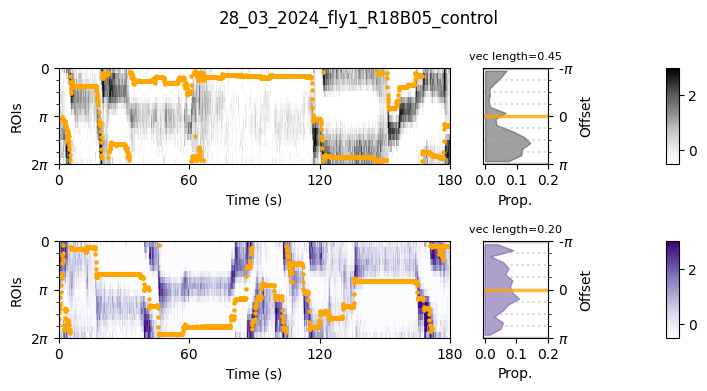

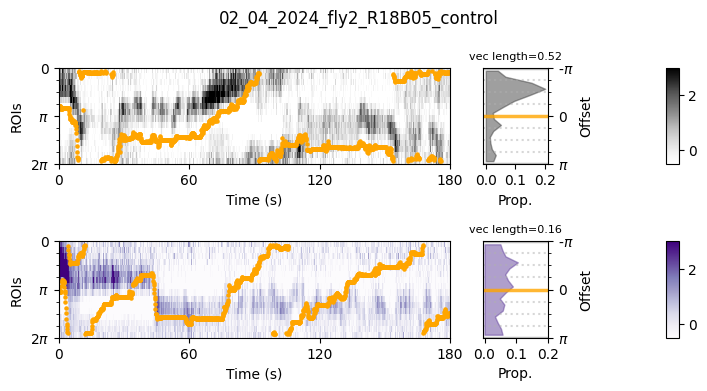

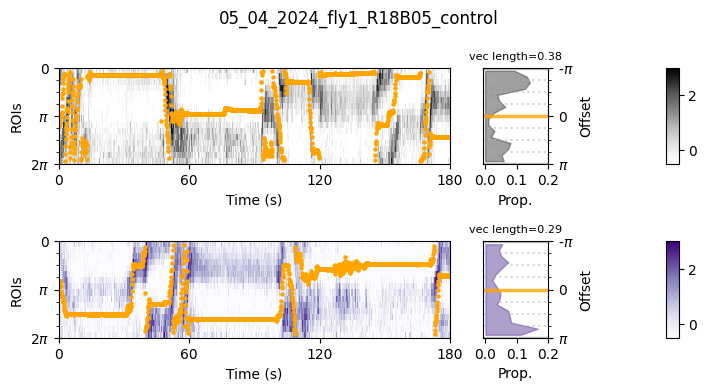

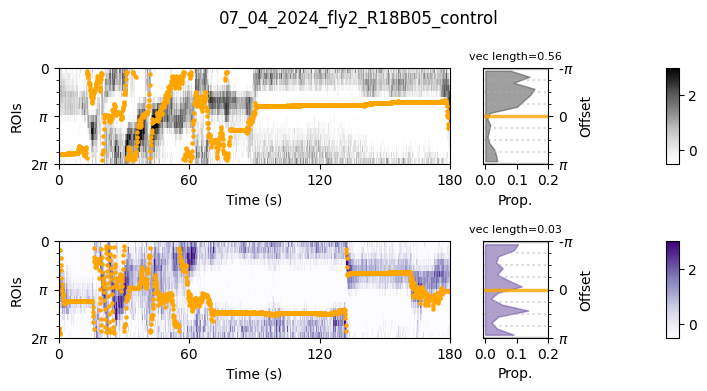

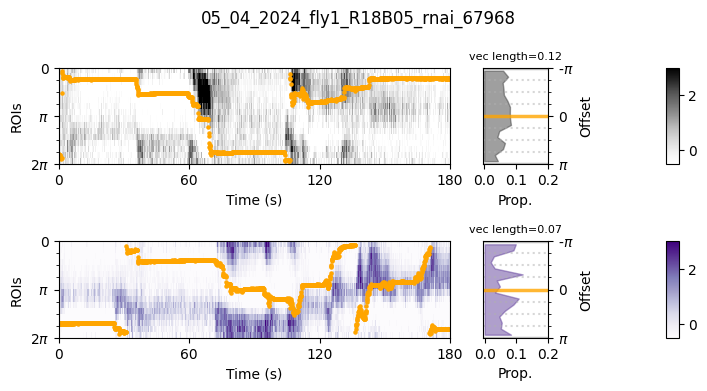

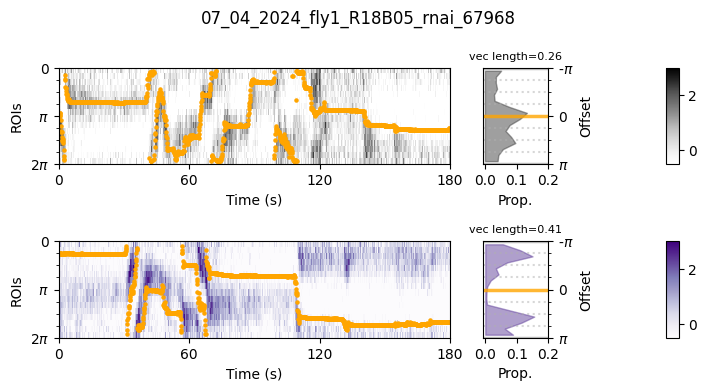

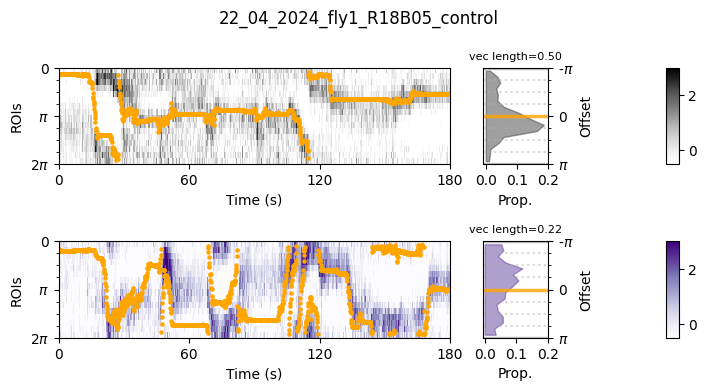

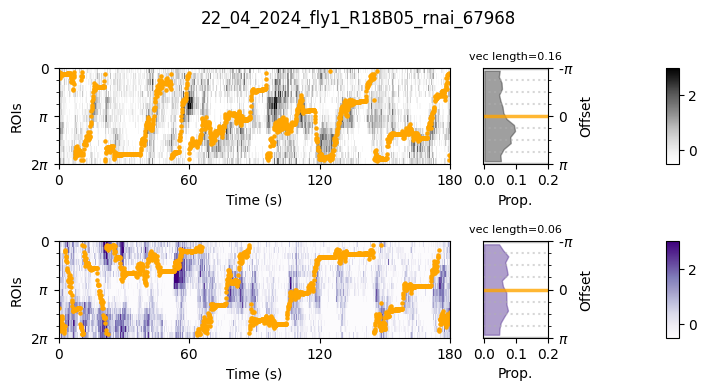

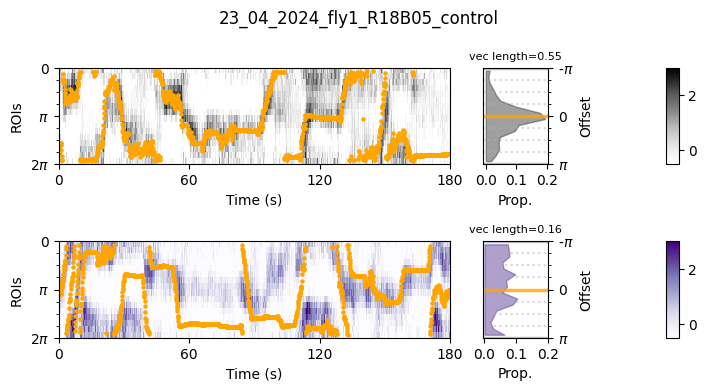

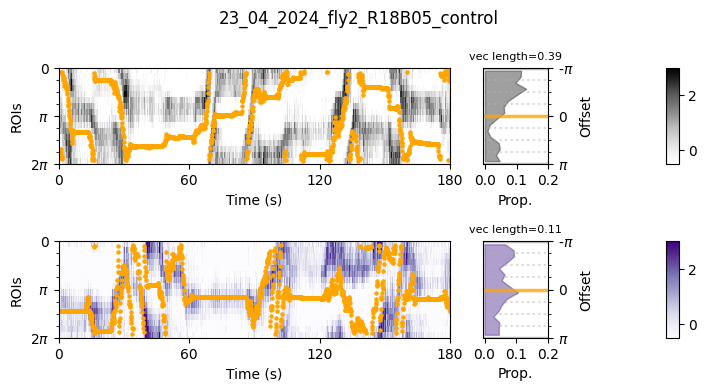

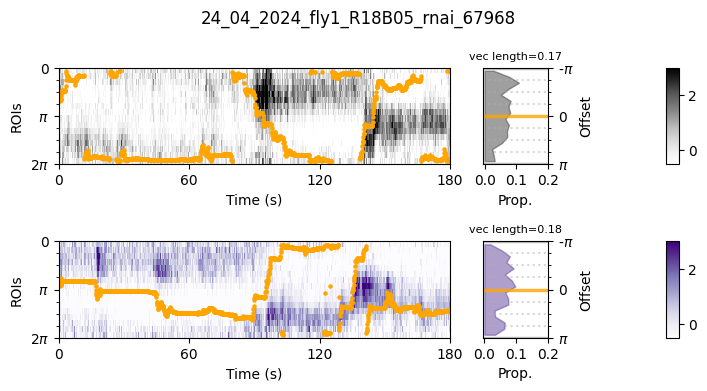

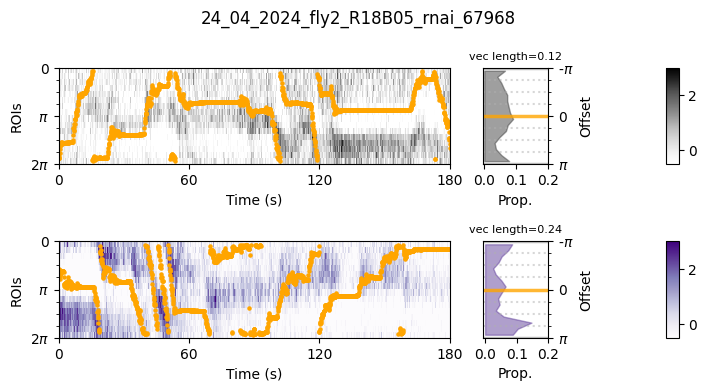

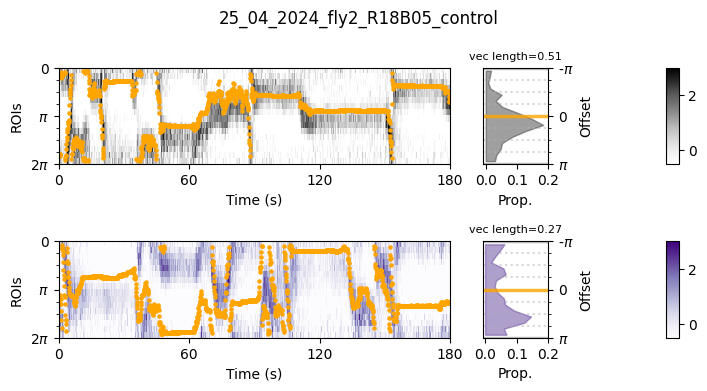

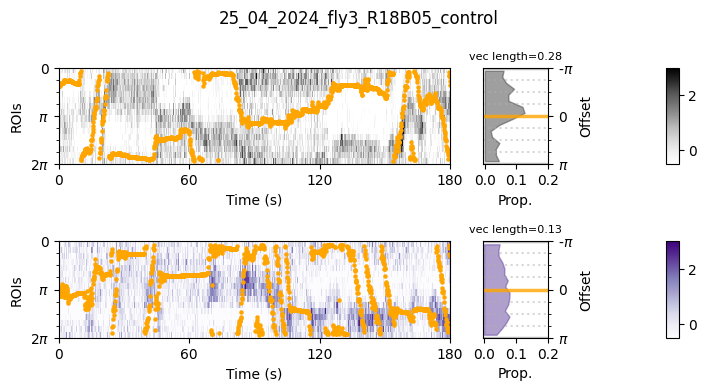

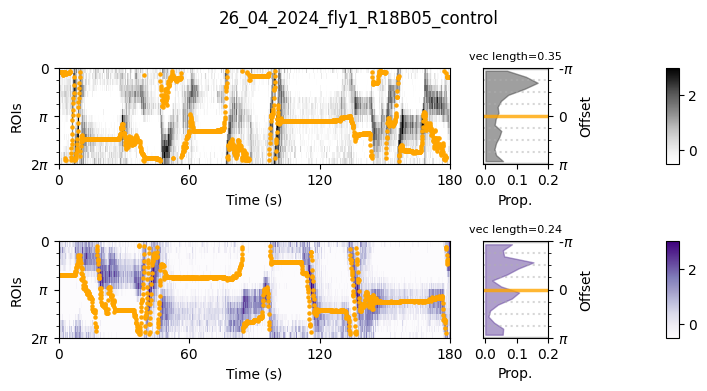

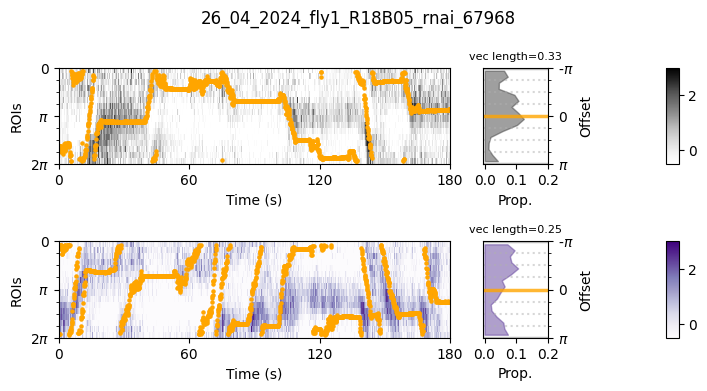

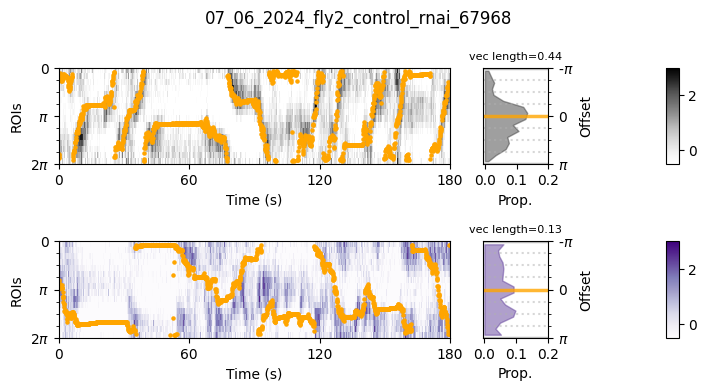

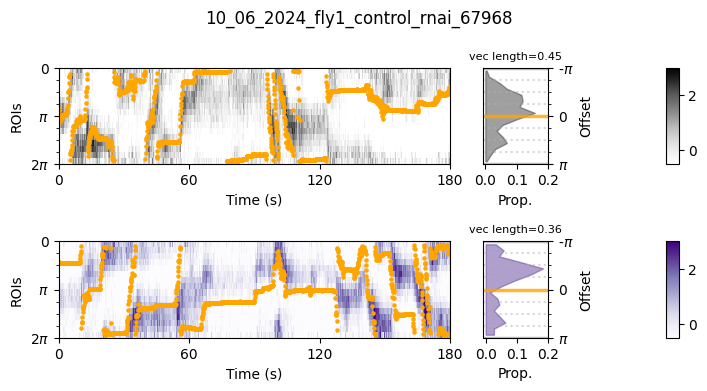

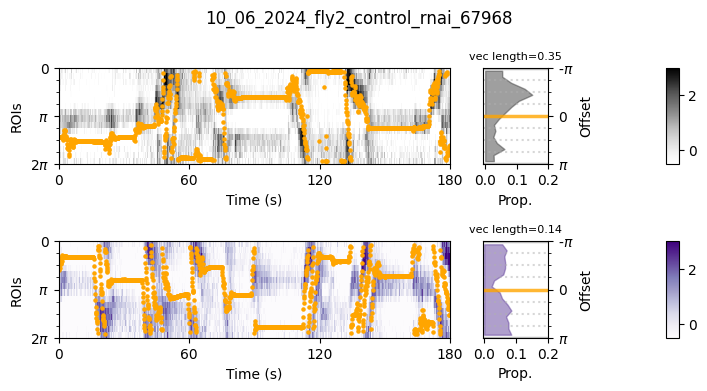

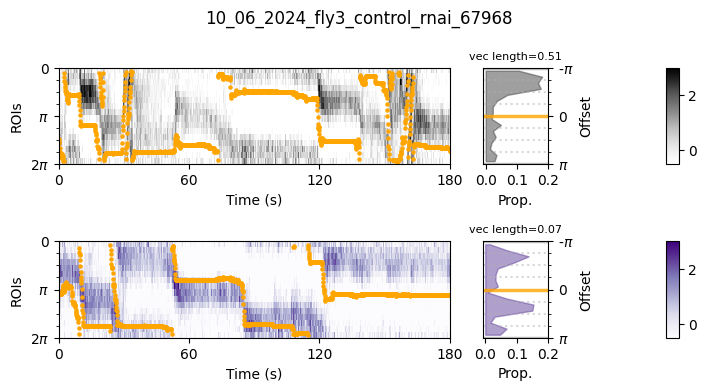

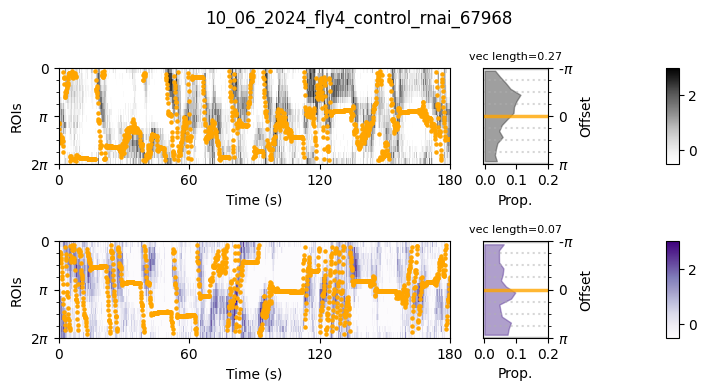

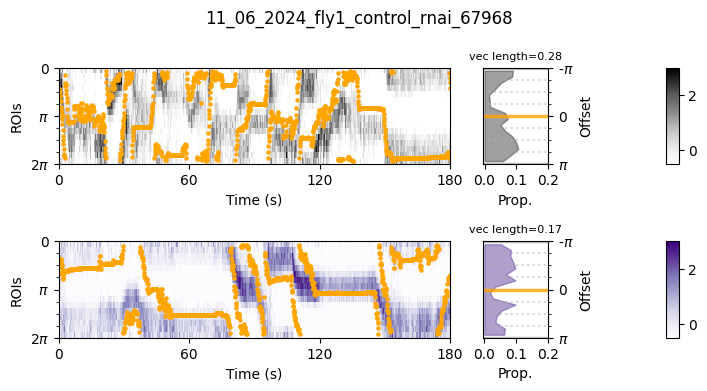

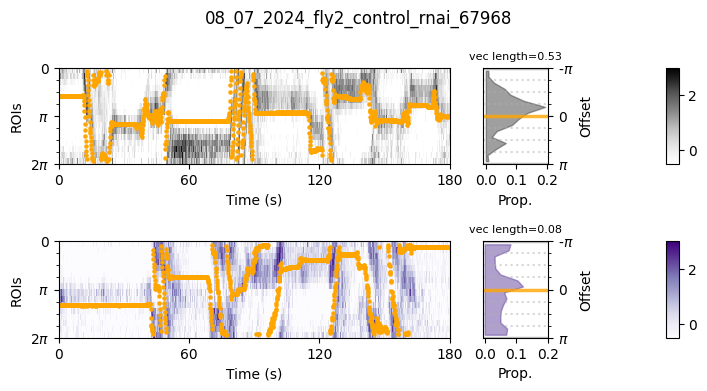

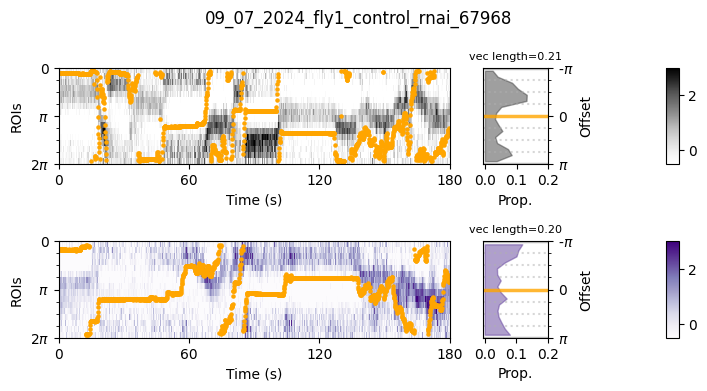

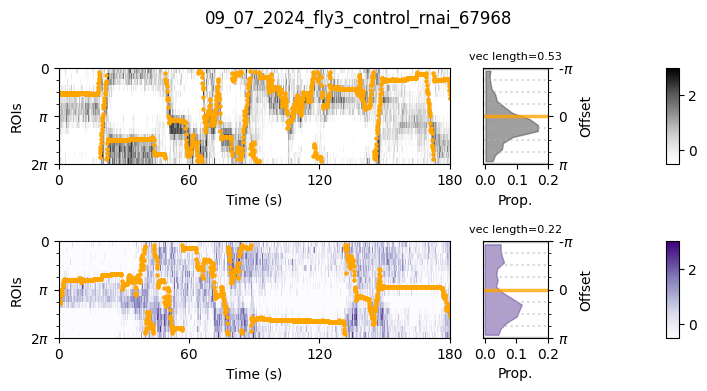

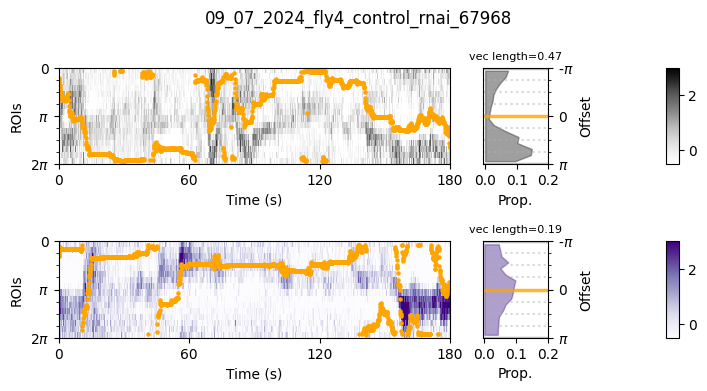

In [9]:
plotted_flies = ana.plot_session_figures(sess_manager, close=False)
len(plotted_flies)